**For generating plots using Wandb csv.file**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def find_column(df, keyword, metric_type='reward', exclude=None):
    """
    keyword가 포함된 컬럼을 찾되, exclude 키워드가 있다면 제외하는 함수.
    특정 환경 이름(env term) 없이도 모델을 구별할 수 있게 해줍니다.
    """
    target_pattern = f'mean_episode_{metric_type}'
    
    for col in df.columns:
        # 1. 기본 조건: 키워드와 메트릭 타입 포함 여부 확인
        if keyword in col and target_pattern in col:
            # 2. 통계 컬럼(MIN, MAX 등) 제외
            if 'MIN' in col or 'MAX' in col or '_step' in col:
                continue
            
            # 3. 제외 키워드(exclude) 확인 (예: 'mappo' 찾을 때 'pci' 제외)
            if exclude and exclude in col:
                continue
                
            return col
    return None

def plot(df_reward, df_length, models_config, lims, window_size=50):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    (r_xlim, r_ylim) = lims['reward']
    (ep_xlim, ep_ylim) = lims['episode']
    
    # --- Plot 1: Reward ---
    for label, config in models_config.items():
        kw = config['keyword']
        exc = config.get('exclude') # exclude 키워드가 없으면 None
        color = config['color']
        
        col = find_column(df_reward, kw, 'reward', exclude=exc)
        if col:
            x = df_reward['total_steps']
            y = df_reward[col]
            
            y_mean = y.rolling(window=window_size, min_periods=1).mean()
            y_std = y.rolling(window=window_size, min_periods=1).std()
            
            ax1.plot(x, y_mean, label=label, color=color, linewidth=2)
            ax1.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.2)

    ax1.set_title(f'Mean Episode Reward')
    ax1.set_xlabel('Total Steps')
    ax1.set_ylabel('Mean Episode Reward')
    ax1.legend(loc='lower left')
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1.set_xlim(r_xlim)
    ax1.set_ylim(r_ylim)
    # --- Plot 2: Length ---
    for label, config in models_config.items():
        kw = config['keyword']
        exc = config.get('exclude')
        color = config['color']
        
        col = find_column(df_length, kw, 'length', exclude=exc)
        if col:
            x = df_length['total_steps']
            y = df_length[col]
            
            y_mean = y.rolling(window=window_size, min_periods=1).mean()
            y_std = y.rolling(window=window_size, min_periods=1).std()
            
            ax2.plot(x, y_mean, label=label, color=color, linewidth=2)
            ax2.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.2)

    ax2.set_title(f'Mean Episode Length')
    ax2.set_xlabel('Total Steps')
    ax2.set_ylabel('Mean Episode Length')
    ax2.legend(loc='lower left')
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.set_xlim(ep_xlim)
    ax2.set_ylim(ep_ylim)

    plt.tight_layout()
    plt.show()

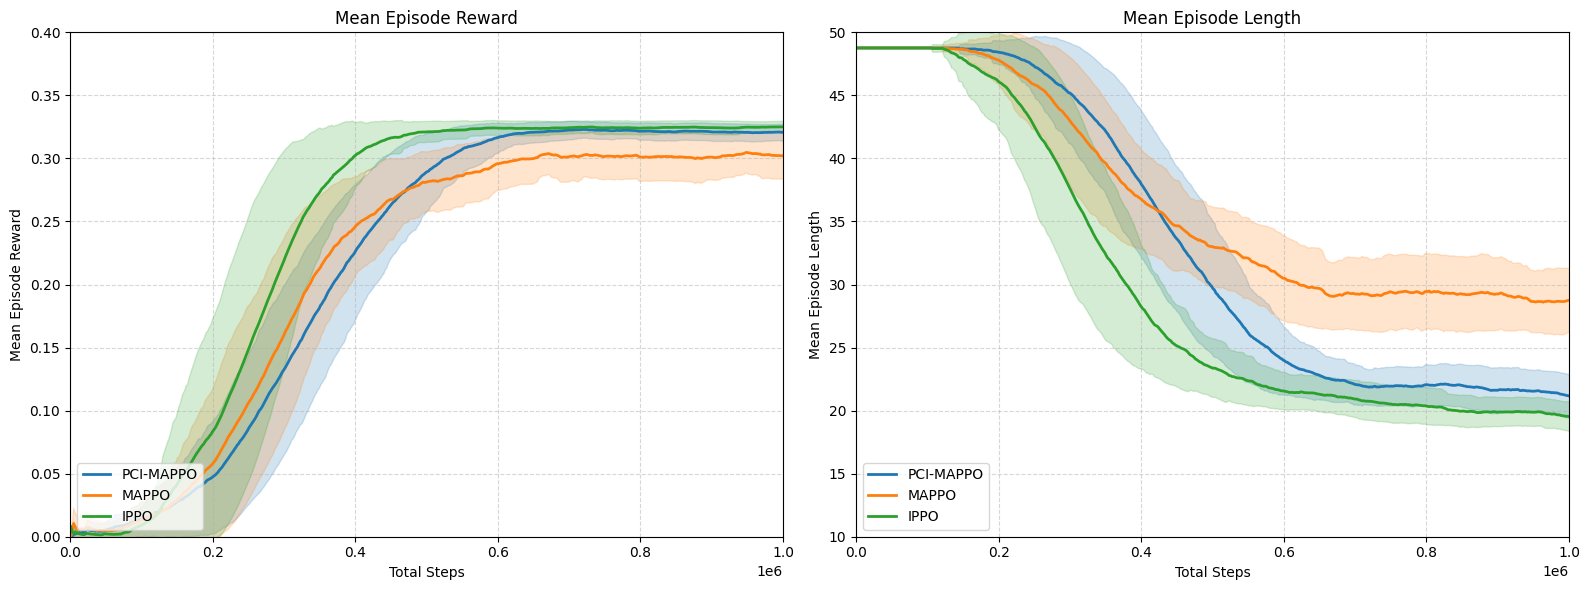

In [25]:
# 데이터 로드
csv_dir = 'wandb_csv'
reward_file = os.path.join(csv_dir, 'lbf_episode_reward.csv')
length_file = os.path.join(csv_dir, 'lbf_episode_length.csv')
df_reward = pd.read_csv(reward_file)
df_length = pd.read_csv(length_file)

# 모델 설정: 'exclude' 옵션을 사용하여 특정 환경 이름 없이 구분
models_config = {
    "PCI-MAPPO": {"keyword": "pci_mappo", "color": "tab:blue"},
    "MAPPO":     {"keyword": "mappo", "exclude": "pci", "color": "tab:orange"}, # 'pci'가 없는 'mappo'만 선택
    "IPPO":      {"keyword": "ippo", "color": "tab:green"},
}

# 그래프 그리기
timesteps = 1000000
lims = {'reward': ((0, timesteps), (0, 0.4)), 'episode': ((0, timesteps), (10, 50))}
plot(df_reward, df_length, models_config, lims, window_size=100)